In [16]:
import time
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
Q = []
R = []

In [17]:
x = [-2.1, -1,  4.3]
y = [3,  1.1,  0.12]
X = np.stack((x, y), axis=0)
X
np.cov(X), np.cov(x, y)
# np.cov(x)

(array([[11.71      , -4.286     ],
        [-4.286     ,  2.14413333]]),
 array([[11.71      , -4.286     ],
        [-4.286     ,  2.14413333]]))

In [34]:
x = np.array([13+3/70, 13+2/57, 13-2/43, 13-3/28, 13+1/15])
y = np.array([27+3/60, 13+2/67, 13-2/33, 13-3/38, 13+1/25])
theta = np.array([np.pi+1/24, np.pi-1/18, np.pi-1/13, np.pi+1/14, np.pi+1/11])
theta = np.array([-np.pi+1/24, np.pi-1/18, np.pi-1/13, -np.pi+1/14, -np.pi+1/11])

In [35]:
dth = np.angle(np.exp(1j*(theta - np.angle(np.mean(np.exp(1j*theta))))))
dth, np.cov(dth), np.cov(theta)

(array([ 0.02734671, -0.06987551, -0.09124304,  0.05710861,  0.07658913]),
 array(0.00577075),
 array(11.34322029))

In [38]:
np.round(np.cov(np.stack((x, y, theta), axis=0)), 3)
# np.round(np.cov(np.stack((x, y, dth), axis=0)), 3)

array([[ 5.0000e-03,  1.6100e-01, -1.2000e-02],
       [ 1.6100e-01,  3.9581e+01, -8.7360e+00],
       [-1.2000e-02, -8.7360e+00,  1.1343e+01]])

In [33]:
np.round(np.cov(np.stack((x-x.mean(), y-y.mean(), dth), axis=0)), 3)

array([[5.0000e-03, 1.6100e-01, 0.0000e+00],
       [1.6100e-01, 3.9581e+01, 9.7000e-02],
       [0.0000e+00, 9.7000e-02, 6.0000e-03]])

In [21]:
np.angle(np.mean(np.exp(1j*theta)))

-3.127272694512819

In [7]:
thymio_data = []

def get_data():
    thymio_data.append({"ground":list(node["prox.ground.reflected"]), 
                        "sensor":list(node["prox.ground.reflected"]),
                        "left_speed":node["motor.left.speed"],
                        "right_speed":node["motor.right.speed"]})

In [ ]:
L = 93
var_r, var_l = 0, 0
m = np.zeros((3, 3))
M = np.array([[var_r, 0], [0, var_l]])
R = np.cov(m)

In [4]:
def wrap_angle(a):
    return (a + np.pi) % (2 * np.pi) - np.pi

In [5]:
def f(x, y, theta, v_r, v_l, dt, L=L):
    f = np.array([x + (v_r + v_l) * np.cos(theta) * dt / 2, 
         y + (v_r + v_l) * np.sin(theta) * dt / 2, 
         wrap_angle(theta + (v_r - v_l) * dt / L)])
    return f

In [137]:
def kalman_(x_old, v_r, v_l, P_old, dt, M=M, R=R, x_measured=None):
    # Units : 
    # x, y, L in mm; theta in radian (-π, π)
    # v_r, v_l in mm/s
    # dt in s
    # M in (mm/s)^2
    # R and P in diag(mm^2, mm^2, rad^2)
    # All arrays should be NumPy arrays of floats
    x, y, theta = x_old[0], x_old[1], x_old[2]
    G = np.array([[np.cos(theta) * dt / 2, np.cos(theta) * dt / 2], 
                  [np.sin(theta) * dt / 2, np.sin(theta) * dt / 2], 
                  [dt / L, -dt / L]])
    F = np.array([[1, 0, -(v_r + v_l) * np.sin(theta) * dt / 2], 
         [0, 1, (v_r + v_l) * np.cos(theta) * dt / 2], 
         [0, 0, 1]])
    x_pred = f(x, y, theta, v_r, v_l, dt)
    P_pred = F @ P_old @ F.T + G @ M @ G.T
    if x_measured is not None:
        i = x_measured - x_pred
        i[2] = wrap_angle(i[2])
        S = P_pred + R
        K = P_pred @ np.linalg.inv(S)
        x_est = x_pred + K @ i
        x_est[2] = wrap_angle(x_est[2])
        P_est = (np.identity(3) - K) @ P_pred
        return x_est, P_est
    else : 
        return x_pred, P_pred

In [138]:
np.random.seed(0)                     # same random numbers each run (easier to debug)

N, dt = 300, 0.1                      # 30 s
L = 93
var_wheel = 7.0                       # (mm/s)^2, the noise you put on the wheel speeds
var_cam = np.array([4.0, 4.0, 0.0004])  # mm^2, mm^2, rad^2 (σ = 2 mm, 2 mm, 0.02 rad)

M = np.diag([var_wheel, var_wheel])
R = np.diag(var_cam)

# "true" wheel speeds: a gentle left curve (mm/s)
v_r_true = np.full(N, 80.0)
v_l_true = np.full(N, 72.0)

# true trajectory, with no noise
x_true = np.zeros((N, 3))
x_true[0] = [0.0, 0.0, 0.0]
for k in range(1, N):
    x_true[k] = f(*x_true[k-1], v_r_true[k], v_l_true[k], dt)

# noisy measurements
v_r_meas = v_r_true + np.random.normal(0, np.sqrt(M[0,0]), N)
v_l_meas = v_l_true + np.random.normal(0, np.sqrt(M[1,1]), N)
cam = x_true + np.random.normal(0, np.sqrt(var_cam), (N, 3))
cam[:, 2] = wrap_angle(cam[:, 2])

In [139]:
# x_pred = x_true[0]
# P_pred = np.diag([1, 1, 0.001])
# pos_est = [x_pred]
# Ps = [P_pred]
# for k in range(N):
#     pos_est.append(x_pred)
#     Ps.append(P_pred)
#     x_pred, P_pred = kalman(x_pred, v_r_meas[k], v_l_meas[k], P_pred, dt, x_measured=cam[k])

# pos_est = np.array(pos_est)
# Ps = np.array(Ps)

x_est = x_true[0].copy()
P = np.diag([1.0, 1.0, 0.001])
pos_est, Ps = [x_est], [P]

for k in range(1, N):
    x_measured = None if 100 <= k < 200 else cam[k]
    x_est, P = kalman_(x_est, v_r_meas[k], v_l_meas[k], P, dt, x_measured=x_measured)
    pos_est.append(x_est)
    Ps.append(P)

pos_est = np.array(pos_est)   
Ps = np.array(Ps)

In [140]:
x = np.array([vec[0] for vec in x_true])
y = np.array([vec[1] for vec in x_true])
theta = np.array([vec[2] for vec in x_true])

x_est = np.array([vec[0] for vec in pos_est])
y_est = np.array([vec[1] for vec in pos_est])
theta_est = np.array([vec[2] for vec in pos_est])

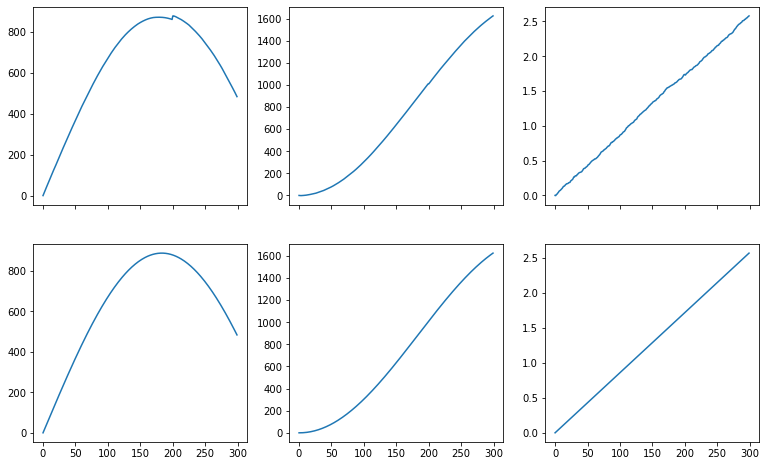

In [141]:
fig, ax = plt.subplots(2, 3, sharex=True, sharey=False, figsize=(13, 8))
ax[0, 0].plot(x_est)
ax[0, 1].plot(y_est)
ax[0, 2].plot(theta_est)
ax[1, 0].plot(x)
ax[1,1].plot(y)
ax[1, 2].plot(theta)
plt.show()

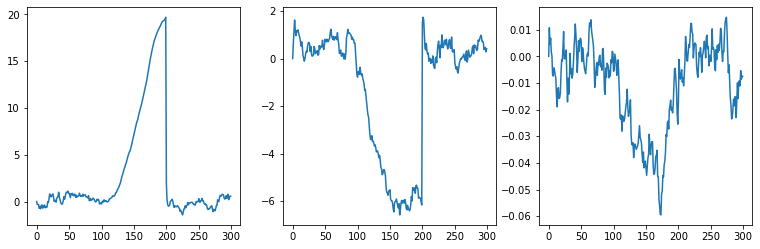

In [114]:
fig, ax = plt.subplots(1, 3, sharex=True, sharey=False, figsize=(13, 4))
ax[0].plot(x-x_est)
ax[1].plot(y-y_est)
ax[2].plot(theta-theta_est)

RMS error camera  : [1.87060969 2.05310331 0.01851837]
RMS error estimate: [6.23531177 2.89877409 0.01949688]


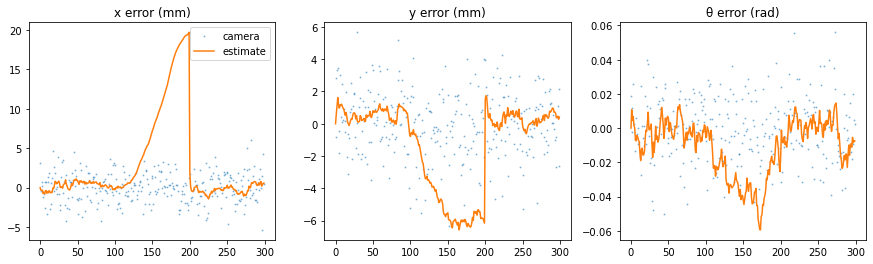

In [115]:
err_est = x_true - pos_est
err_cam = x_true - cam
err_est[:, 2] = wrap_angle(err_est[:, 2])
err_cam[:, 2] = wrap_angle(err_cam[:, 2])

rms = lambda e: np.sqrt(np.mean(e**2, axis=0))
print("RMS error camera  :", rms(err_cam[1:]))
print("RMS error estimate:", rms(err_est[1:]))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for j, name in enumerate(["x error (mm)", "y error (mm)", "θ error (rad)"]):
    ax[j].plot(err_cam[:, j], ".", markersize=2, alpha=0.4, label="camera")
    ax[j].plot(err_est[:, j], label="estimate")
    ax[j].set_title(name)
ax[0].legend()
plt.show()

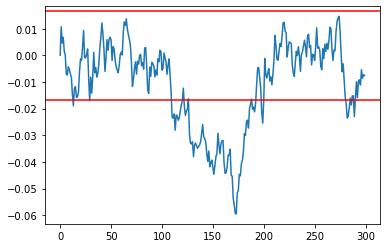

In [116]:
pos_est = np.array(pos_est)
plt.plot(err_est[:,2])
plt.axhline(y=2*np.sqrt(np.array(Ps[k])[2,2]), color='r')
plt.axhline(y=-2*np.sqrt(np.array(Ps[k])[2,2]), color='r')
plt.show()

In [104]:
len(pos_est)

300

In [105]:
x = np.array([vec[0] for vec in x_true])
y = np.array([vec[1] for vec in x_true])
theta = np.array([vec[2] for vec in x_true])

x_est = np.array([vec[0] for vec in pos_est])
y_est = np.array([vec[1] for vec in pos_est])
theta_est = np.array([vec[2] for vec in pos_est])

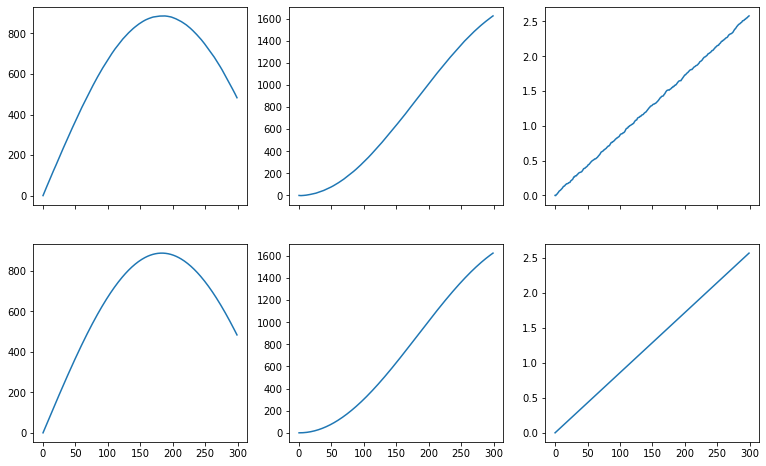

In [106]:
fig, ax = plt.subplots(2, 3, sharex=True, sharey=False, figsize=(13, 8))
ax[0, 0].plot(x_est)
ax[0, 1].plot(y_est)
ax[0, 2].plot(theta_est)
ax[1, 0].plot(x)
ax[1,1].plot(y)
ax[1, 2].plot(theta)
plt.show()

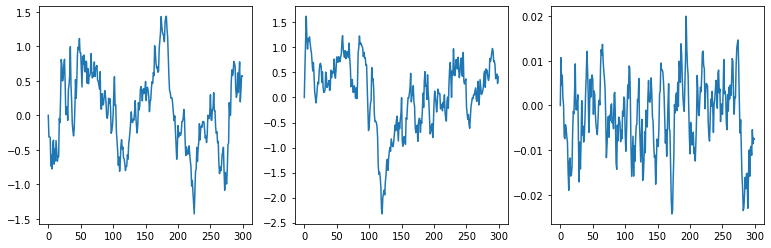

In [108]:
fig, ax = plt.subplots(1, 3, sharex=True, sharey=False, figsize=(13, 4))
ax[0].plot(x-x_est[:])
ax[1].plot(y-y_est[:])
ax[2].plot(theta-theta_est[:])

RMS error camera  : [1.87060969 2.05310331 0.01851837]
RMS error estimate: [0.57406775 0.70031114 0.00848756]


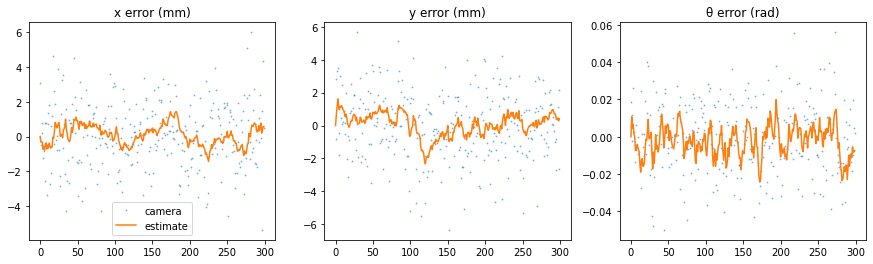

In [109]:
err_est = x_true - pos_est
err_cam = x_true - cam
err_est[:, 2] = wrap_angle(err_est[:, 2])
err_cam[:, 2] = wrap_angle(err_cam[:, 2])

rms = lambda e: np.sqrt(np.mean(e**2, axis=0))
print("RMS error camera  :", rms(err_cam[1:]))
print("RMS error estimate:", rms(err_est[1:]))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for j, name in enumerate(["x error (mm)", "y error (mm)", "θ error (rad)"]):
    ax[j].plot(err_cam[:, j], ".", markersize=2, alpha=0.4, label="camera")
    ax[j].plot(err_est[:, j], label="estimate")
    ax[j].set_title(name)
ax[0].legend()
plt.show()

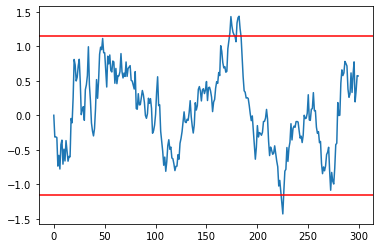

In [110]:
pos_est = np.array(pos_est)
plt.plot(err_est[:,0])
plt.axhline(y=2*np.sqrt(np.array(Ps[k])[0,0]), color='r')
plt.axhline(y=-2*np.sqrt(np.array(Ps[k])[0,0]), color='r')
plt.show()

In [117]:
var_array = np.load('/Users/mathias/Desktop/EPFL/Ma3/Basics of mobile robotics/Exos/8/Exercises-20/wheels variances.npy')

In [119]:
np.save('wheels variances', var_array)

In [160]:
import numpy as np

var_array = np.load('/Users/mathias/Desktop/EPFL/Ma3/Basics of mobile robotics/MICRO-452/src/mrproject/wheels variances.npy')
var_l_speed, var_r_speed, var_speed = var_array
L = 93

m = np.zeros((3, 3))
M = np.load('M.npy')
R = np.diag([0.01, 0.01, 1e-5])

def wrap_angle(a):
    return (a + np.pi) % (2 * np.pi) - np.pi

def f(x, y, theta, v_r, v_l, dt, L=L):
    f = np.array([x + (v_r + v_l) * np.cos(theta) * dt / 2, 
         y + (v_r + v_l) * np.sin(theta) * dt / 2, 
         wrap_angle(theta + (v_r - v_l) * dt / L)])
    return f

def kalman_f(x_old, v_r, v_l, P_old, dt, M=M, R=R, x_measured=None):
    x, y, theta = x_old[0], x_old[1], x_old[2]
    G = np.array([[np.cos(theta) * dt / 2, np.cos(theta) * dt / 2], 
                  [np.sin(theta) * dt / 2, np.sin(theta) * dt / 2], 
                  [dt / L, -dt / L]])
    F = np.array([[1, 0, -(v_r + v_l) * np.sin(theta) * dt / 2], 
         [0, 1, (v_r + v_l) * np.cos(theta) * dt / 2], 
         [0, 0, 1]])
    x_pred = f(x, y, theta, v_r, v_l, dt)
    P_pred = F @ P_old @ F.T + G @ M @ G.T
    if x_measured is not None:
        i = x_measured - x_pred
        i[2] = wrap_angle(i[2])
        S = P_pred + R
        K = P_pred @ np.linalg.inv(S)
        x_est = x_pred + K @ i
        x_est[2] = wrap_angle(x_est[2])
        P_est = (np.identity(3) - K) @ P_pred
        return x_est, P_est
    else : 
        return x_pred, P_pred

In [176]:
np.random.seed(0)                     # same random numbers each run (easier to debug)

N, dt = 300, 0.1                      # 30 s

# "true" wheel speeds: a gentle left curve (mm/s)
v_r_true = np.full(N, 80.0)
v_l_true = np.full(N, 72.0)

# true trajectory, with no noise
x_true = np.zeros((N, 3))
x_true[0] = [0.0, 0.0, 0.0]
for k in range(1, N):
    x_true[k] = f(*x_true[k-1], v_r_true[k], v_l_true[k], dt)

# noisy measurements
v_r_meas = v_r_true + np.random.normal(0, np.sqrt(M[0,0]), N)
v_l_meas = v_l_true + np.random.normal(0, np.sqrt(M[1,1]), N)
cam = x_true + np.random.normal(0, np.sqrt(R.diagonal()), (N, 3))
cam[:, 2] = wrap_angle(cam[:, 2])

In [178]:
x_est = x_true[0].copy()
P = np.diag([1.0, 1.0, 0.001])
pos_est, Ps = [x_est], [P]

for k in range(1, N):
    x_measured = cam[k] if k%4==0 else None
    x_est, P = kalman_f(x_est, v_r_meas[k], v_l_meas[k], P, dt, x_measured=x_measured)
    pos_est.append(x_est)
    Ps.append(P)

pos_est = np.array(pos_est)   
Ps = np.array(Ps)

In [179]:
x, y, theta = x_true[:, 0], x_true[:, 1], x_true[:, 2]
x_est, y_est, theta_est = pos_est[:, 0], pos_est[:, 1], pos_est[:, 2]

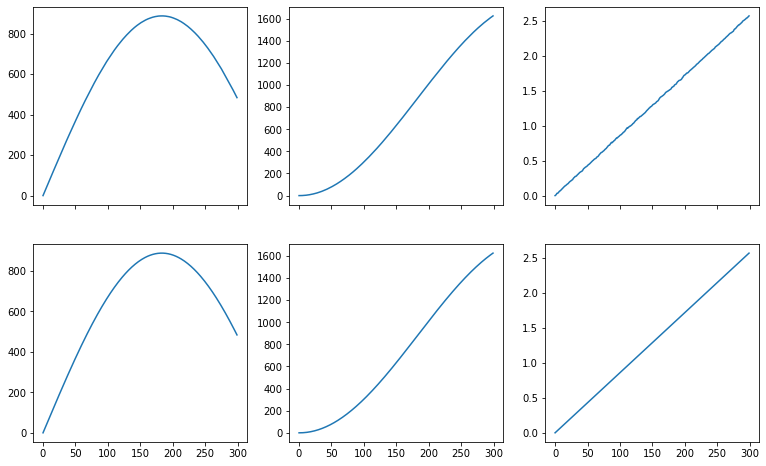

In [180]:
fig, ax = plt.subplots(2, 3, sharex=True, sharey=False, figsize=(13, 8))
ax[0, 0].plot(x_est)
ax[0, 1].plot(y_est)
ax[0, 2].plot(theta_est)
ax[1, 0].plot(x)
ax[1,1].plot(y)
ax[1, 2].plot(theta)
plt.show()

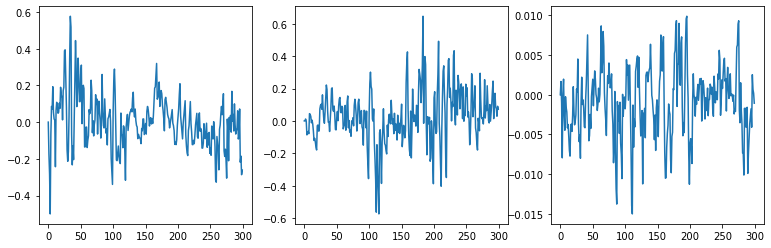

In [181]:
fig, ax = plt.subplots(1, 3, sharex=True, sharey=False, figsize=(13, 4))
ax[0].plot(x-x_est[:])
ax[1].plot(y-y_est[:])
ax[2].plot(theta-theta_est[:])

RMS error camera  : [0.09353048 0.10265517 0.00292801]
RMS error estimate: [0.14384146 0.16583009 0.00443013]


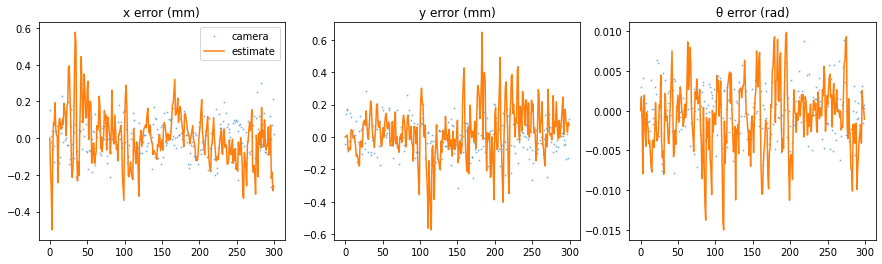

In [182]:
err_est = x_true - pos_est
err_cam = x_true - cam
err_est[:, 2] = wrap_angle(err_est[:, 2])
err_cam[:, 2] = wrap_angle(err_cam[:, 2])

rms = lambda e: np.sqrt(np.mean(e**2, axis=0))
print("RMS error camera  :", rms(err_cam[1:]))
print("RMS error estimate:", rms(err_est[1:]))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for j, name in enumerate(["x error (mm)", "y error (mm)", "θ error (rad)"]):
    ax[j].plot(err_cam[:, j], ".", markersize=2, alpha=0.4, label="camera")
    ax[j].plot(err_est[:, j], label="estimate")
    ax[j].set_title(name)
ax[0].legend()
plt.show()

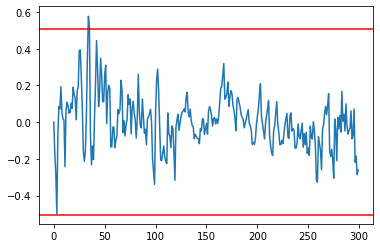

In [183]:
pos_est = np.array(pos_est)
plt.plot(err_est[:,0])
plt.axhline(y=2*np.sqrt(np.array(Ps[k])[0,0]), color='r')
plt.axhline(y=-2*np.sqrt(np.array(Ps[k])[0,0]), color='r')
plt.show()